# Mini Project 8 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_08.py` (bagian wajib) dan `features/mp08_extension_feature_analysis.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 8 — Menetapkan Feature Schema untuk Keyword Spotting
Membaca frame baku MP7 (tanpa preprocessing ulang), menghitung RMS, ZCR, centroid,
bandwidth, roll-off, log-Mel (26), 13 MFCC, pitch autokorelasi, lalu menyusun vektor
tetap 39-D. Status diubah menjadi `ready_for_mp09`.

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import json
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.fft import dct

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
STATUS = ROOT / 'project_status.json'

## Langkah 1 — Validasi artefak MP7

In [2]:
status = json.loads(STATUS.read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp08', 'ready_for_mp09'), status['status']

frames_path = ROOT / status['mp08_input_frames']
pre_cfg_path = ROOT / status['preprocessing_config']
assert frames_path.exists() and pre_cfg_path.exists()

z = np.load(frames_path, allow_pickle=True)
frames = np.asarray(z['frames'], dtype=np.float64)
fs = int(z['fs'])
frame_len = int(z['frame_length'])
hop_len = int(z['hop_length'])
assert frames.ndim == 2 and frames.shape[1] == frame_len
assert np.isfinite(frames).all()

pre_cfg = json.loads(pre_cfg_path.read_text(encoding='utf-8'))
assert int(pre_cfg['sampling_rate_hz']) == fs
print('Frame input:', frames.shape, '| fs =', fs, '| frame/hop =', frame_len, '/', hop_len)

Frame input: (60, 400) | fs = 16000 | frame/hop = 400 / 160


## 1) Fitur frame dasar: RMS, ZCR, centroid, bandwidth, roll-off 85%

In [3]:
rms = np.sqrt(np.mean(frames**2, axis=1) + 1e-12)
zcr = np.mean(np.abs(np.diff(np.signbit(frames), axis=1)), axis=1)

freq = np.fft.rfftfreq(frame_len, d=1.0/fs)
X = np.fft.rfft(frames, axis=1)
power = (np.abs(X) ** 2) + 1e-15
psum = np.sum(power, axis=1) + 1e-15
centroid = np.sum(power * freq[None, :], axis=1) / psum
bandwidth = np.sqrt(np.sum(power * (freq[None, :] - centroid[:, None])**2,
                           axis=1) / psum)

cum = np.cumsum(power, axis=1)
rolloff = np.empty(len(frames), dtype=np.float64)
for i in range(len(frames)):
    idx = int(np.searchsorted(cum[i], 0.85 * cum[i, -1]))
    rolloff[i] = freq[min(idx, len(freq)-1)]

## 2) Mel filterbank, log-Mel, MFCC

In [4]:
def hz_to_mel(f):
    return 2595.0 * np.log10(1.0 + np.asarray(f) / 700.0)


def mel_to_hz(m):
    return 700.0 * (10.0**(np.asarray(m) / 2595.0) - 1.0)


def make_mel_filterbank(n_fft, fs, n_mels=26, fmin=80.0, fmax=7600.0):
    n_bins = n_fft // 2 + 1
    mel_pts = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    hz_pts = mel_to_hz(mel_pts)
    bins = np.floor((n_fft + 1) * hz_pts / fs).astype(int)
    bins = np.clip(bins, 0, n_bins - 1)
    fb = np.zeros((n_mels, n_bins), dtype=np.float64)
    for m in range(1, n_mels + 1):
        left, center, right = bins[m-1], bins[m], bins[m+1]
        center = max(center, left + 1)
        right = max(right, center + 1)
        right = min(right, n_bins - 1)
        for k in range(left, min(center, n_bins)):
            fb[m-1, k] = (k - left) / max(1, center - left)
        for k in range(center, min(right + 1, n_bins)):
            fb[m-1, k] = (right - k) / max(1, right - center)
    return fb


n_mels = 26
n_mfcc = 13
fmin = 80.0
fmax = min(7600.0, 0.95 * fs/2)
fb = make_mel_filterbank(frame_len, fs, n_mels, fmin, fmax)
mel_energy = np.maximum(power @ fb.T, 1e-12)
log_mel = np.log(mel_energy)
mfcc = dct(log_mel, type=2, axis=1, norm='ortho')[:, :n_mfcc]

## 3) Pitch via autokorelasi (80–350 Hz, confidence ≥ 0.25)

In [5]:
pitch_min_hz = 80.0
pitch_max_hz = 350.0
lag_min = max(1, int(fs / pitch_max_hz))
lag_max = min(frame_len - 2, int(fs / pitch_min_hz))
pitch_hz = np.zeros(len(frames), dtype=np.float64)
pitch_conf = np.zeros(len(frames), dtype=np.float64)
energy_floor = float(np.percentile(rms, 25))

for i, fr in enumerate(frames):
    if rms[i] <= energy_floor:
        continue
    ac = np.correlate(fr, fr, mode='full')[frame_len-1:]
    if ac[0] <= 1e-12:
        continue
    ac = ac / ac[0]
    search = ac[lag_min:lag_max+1]
    if len(search) == 0:
        continue
    lag = int(np.argmax(search)) + lag_min
    conf = float(ac[lag])
    pitch_conf[i] = conf
    if conf >= 0.25:
        pitch_hz[i] = fs / lag

voiced = pitch_hz > 0
voiced_ratio = float(np.mean(voiced))

## 4) Agregasi menjadi vektor tetap 39-D (mean/std + voiced ratio)

In [6]:
feature_names = []
feature_values = []


def add_mean_std(prefix, arr, mask=None):
    a = np.asarray(arr, dtype=np.float64)
    if mask is not None:
        a = a[np.asarray(mask, dtype=bool)]
    if a.size == 0:
        mu, sd = 0.0, 0.0
    else:
        mu, sd = float(np.mean(a)), float(np.std(a))
    feature_names.extend([prefix + '_mean', prefix + '_std'])
    feature_values.extend([mu, sd])


for j in range(n_mfcc):
    add_mean_std(f'mfcc{j+1:02d}', mfcc[:, j])
add_mean_std('rms', rms)
add_mean_std('zcr', zcr)
add_mean_std('centroid_hz', centroid)
add_mean_std('bandwidth_hz', bandwidth)
add_mean_std('rolloff85_hz', rolloff)
add_mean_std('f0_hz', pitch_hz, voiced)
feature_names.append('voiced_ratio')
feature_values.append(voiced_ratio)

feature_values = np.asarray(feature_values, dtype=np.float32)
feature_names = np.asarray(feature_names, dtype=object)
assert feature_values.shape == (39,), feature_values.shape
assert len(feature_names) == 39
assert np.isfinite(feature_values).all()

## 5) Simpan artefak: feature_config, frame features, sample vector, metrik

In [7]:
config_dir = ROOT / 'config'; config_dir.mkdir(parents=True, exist_ok=True)
feat_dir = ROOT / 'features/intermediate'; feat_dir.mkdir(parents=True, exist_ok=True)
metric_dir = ROOT / 'results/metrics'; metric_dir.mkdir(parents=True, exist_ok=True)
fig_dir = ROOT / 'results/figures'; fig_dir.mkdir(parents=True, exist_ok=True)

feature_cfg = {
    'sampling_rate_hz': fs,
    'frame_length_samples': frame_len,
    'hop_length_samples': hop_len,
    'input_frames_source': frames_path.relative_to(ROOT).as_posix(),
    'power_spectrum': 'abs(rfft(frame))**2',
    'mel': {'n_mels': n_mels, 'fmin_hz': fmin, 'fmax_hz': fmax,
            'scale': '2595*log10(1+f/700)', 'log': 'natural'},
    'mfcc': {'n_mfcc': n_mfcc, 'dct_type': 2, 'norm': 'ortho',
             'delta': False, 'delta_delta': False},
    'spectral': {'centroid': True, 'bandwidth': True, 'rolloff_fraction': 0.85},
    'temporal': {'rms': True, 'zcr': True},
    'pitch': {'method': 'autocorrelation', 'min_hz': pitch_min_hz,
              'max_hz': pitch_max_hz, 'confidence_threshold': 0.25},
    'aggregation': {'statistics': ['mean', 'std'], 'f0_only_voiced': True,
                    'append_voiced_ratio': True},
    'sample_vector_dim': 39,
    'feature_names': feature_names.tolist(),
    'scaling': 'NONE_HERE__fit_only_on_training_set_in_later_chapter'
}
(config_dir / 'feature_config.json').write_text(
    json.dumps(feature_cfg, indent=2), encoding='utf-8')

np.savez(feat_dir / 'mp08_frame_features.npz',
         fs=np.int32(fs),
         rms=rms.astype(np.float32), zcr=zcr.astype(np.float32),
         centroid_hz=centroid.astype(np.float32),
         bandwidth_hz=bandwidth.astype(np.float32),
         rolloff85_hz=rolloff.astype(np.float32),
         pitch_hz=pitch_hz.astype(np.float32),
         pitch_confidence=pitch_conf.astype(np.float32),
         log_mel=log_mel.astype(np.float32),
         mfcc=mfcc.astype(np.float32),
         mel_filterbank=fb.astype(np.float32))

np.savez(feat_dir / 'mp08_sample_feature_vector.npz',
         sample_id='nyala_001', label='nyala',
         values=feature_values, names=feature_names)

metrics = {
    'n_frames': int(len(frames)),
    'frame_feature_shapes': {'log_mel': list(log_mel.shape), 'mfcc': list(mfcc.shape)},
    'sample_vector_dim': int(len(feature_values)),
    'voiced_ratio': voiced_ratio,
    'mean_f0_hz_voiced': float(np.mean(pitch_hz[voiced])) if np.any(voiced) else 0.0,
    'std_f0_hz_voiced': float(np.std(pitch_hz[voiced])) if np.any(voiced) else 0.0,
    'nan_or_inf_count': int(np.size(feature_values) - np.isfinite(feature_values).sum()),
    'feature_names': feature_names.tolist()
}
(metric_dir / 'mp08_feature_metrics.json').write_text(
    json.dumps(metrics, indent=2), encoding='utf-8')

1077

## 6) Visualisasi log-Mel/MFCC dan fitur skalar

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
im0 = axs[0].imshow(log_mel.T, aspect='auto', origin='lower', interpolation='nearest')
axs[0].set_ylabel('Mel bin'); axs[0].set_title('Log-Mel')
fig.colorbar(im0, ax=axs[0], fraction=.025, pad=.02)
im1 = axs[1].imshow(mfcc.T, aspect='auto', origin='lower', interpolation='nearest')
axs[1].set_ylabel('MFCC'); axs[1].set_xlabel('Frame'); axs[1].set_title('13 MFCC')
fig.colorbar(im1, ax=axs[1], fraction=.025, pad=.02)
fig.tight_layout(); fig.savefig(fig_dir/'mp08_logmel_mfcc.png', dpi=180); plt.close(fig)

fig, axs = plt.subplots(3, 1, figsize=(10, 7.2), sharex=True)
axs[0].plot(rms, label='RMS'); axs[0].plot(zcr, label='ZCR'); axs[0].legend(); axs[0].grid(alpha=.2)
axs[1].plot(centroid, label='centroid'); axs[1].plot(bandwidth, label='bandwidth'); axs[1].plot(rolloff, label='rolloff85'); axs[1].set_ylabel('Hz')
axs[1].legend(); axs[1].grid(alpha=.2)
axs[2].plot(np.where(voiced, pitch_hz, np.nan), 'o-', ms=3, label='F0 (voiced only)'); axs[2].set_ylabel('Hz'); axs[2].set_xlabel('Frame'); axs[2].legend(); axs[2].grid(alpha=.2)
fig.tight_layout(); fig.savefig(fig_dir/'mp08_scalar_features.png', dpi=180); plt.close(fig)

## 7) Update serial status -> ready_for_mp09

In [9]:
status.update({
    'status': 'ready_for_mp09',
    'last_completed_mini_project': 8,
    'feature_config': 'config/feature_config.json',
    'frame_features': 'features/intermediate/mp08_frame_features.npz',
    'sample_feature_vector': 'features/intermediate/mp08_sample_feature_vector.npz',
    'feature_metrics': 'results/metrics/mp08_feature_metrics.json',
    'feature_schema_dim': 39,
    'mp09_input_feature_config': 'config/feature_config.json',
    'mp09_reference_feature_vector': 'features/intermediate/mp08_sample_feature_vector.npz',
    'mp09_reference_frame_features': 'features/intermediate/mp08_frame_features.npz'
})
STATUS.write_text(json.dumps(status, indent=2), encoding='utf-8')

print('Frames            :', len(frames))
print('Log-Mel shape     :', log_mel.shape)
print('MFCC shape        :', mfcc.shape)
print('Feature vector dim:', len(feature_values))
print('Voiced ratio      :', round(voiced_ratio, 3))
print('Mean F0 (voiced)  :', round(metrics['mean_f0_hz_voiced'], 1), 'Hz')
print('NaN/Inf count     :', metrics['nan_or_inf_count'])
print('Status            : ready_for_mp09')

Frames            : 60
Log-Mel shape     : (60, 26)
MFCC shape        : (60, 13)
Feature vector dim: 39
Voiced ratio      : 0.633
Mean F0 (voiced)  : 178.7 Hz
NaN/Inf count     : 0
Status            : ready_for_mp09


---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp08_extension_feature_analysis.py`

## FITUR TAMBAHAN MP8 — Extended Features, Biaya Komputasi & Tabel Fitur untuk Firmware
Modul mandiri, dijalankan SETELAH `mini_project_08.py`. Kontrak 39-D **tidak diubah**;
fitur tambahan disimpan terpisah sebagai eksplorasi.

Fitur tambahan (materi Bab 8 yang tidak diminta tugas):
1. **Delta & delta-delta MFCC** (regresi lebar 2) — dinamika spektral.
2. **Spectral flux, spectral flatness, energy contour (dB)** — flux memerlukan state frame sebelumnya.
3. **Pitch YIN (CMNDF)** sebagai pembanding pitch autokorelasi (validasi silang F0).
4. **Profiling biaya komputasi per kelompok fitur** (µs/frame di host) → dasar seleksi hardware-aware MP10.
5. **Uji presisi float32 vs float64** untuk MFCC (simulasi MCU ber-FPU single precision).
6. **Sanity check filterbank & DCT** (cakupan filter, orthonormalitas) +
   export `firmware/mp08_feature_tables.h` (Mel filterbank sparse + matriks DCT float32).

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [10]:
from pathlib import Path
import json
import time
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.fft import dct

ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp09',), 'Jalankan mini_project_08.py terlebih dahulu'
fcfg = json.loads((ROOT/'config/feature_config.json').read_text(encoding='utf-8'))
Z = np.load(ROOT/status['mp08_input_frames'], allow_pickle=True)
frames = Z['frames'].astype(np.float64); fs = int(Z['fs']); N = frames.shape[1]
FF = np.load(ROOT/status['frame_features'], allow_pickle=True)
mfcc = FF['mfcc'].astype(np.float64); log_mel = FF['log_mel'].astype(np.float64)
fb = FF['mel_filterbank'].astype(np.float64); pitch_ac = FF['pitch_hz'].astype(np.float64)
OUT_MET = ROOT/'results/metrics'; OUT_FIG = ROOT/'results/figures'; FW = ROOT/'firmware'
for d in (OUT_MET, OUT_FIG, FW):
    d.mkdir(parents=True, exist_ok=True)
freq = np.fft.rfftfreq(N, 1/fs)
power = np.abs(np.fft.rfft(frames, axis=1))**2 + 1e-15

### 1–2. Delta/delta-delta MFCC, spectral flux, flatness, energy contour

In [11]:
def deltas(feat, width=2):
    """Regresi delta standar (HTK): d_t = sum_n n (c_{t+n}-c_{t-n}) / (2 sum n^2)."""
    T = len(feat)
    pad = np.pad(feat, ((width, width), (0, 0)), mode='edge')
    den = 2*sum(n*n for n in range(1, width+1))
    return np.stack([sum(n*(pad[t+width+n]-pad[t+width-n]) for n in range(1, width+1))/den for t in range(T)])


d_mfcc = deltas(mfcc); dd_mfcc = deltas(d_mfcc)
mag = np.sqrt(power)
mag_n = mag/(mag.sum(axis=1, keepdims=True)+1e-12)
flux = np.r_[0.0, np.sqrt(np.sum(np.diff(mag_n, axis=0).clip(min=0)**2, axis=1))]
flatness = np.exp(np.mean(np.log(power), axis=1))/np.mean(power, axis=1)
energy_db = 10*np.log10(np.mean(frames**2, axis=1)+1e-12)
extended = {
    'delta_mfcc_mean': d_mfcc.mean(axis=0).tolist(), 'delta_mfcc_std': d_mfcc.std(axis=0).tolist(),
    'delta2_mfcc_mean': dd_mfcc.mean(axis=0).tolist(), 'delta2_mfcc_std': dd_mfcc.std(axis=0).tolist(),
    'spectral_flux_mean': float(flux.mean()), 'spectral_flux_std': float(flux.std()),
    'spectral_flatness_mean': float(flatness.mean()), 'spectral_flatness_std': float(flatness.std()),
    'energy_db_range': float(energy_db.max()-energy_db.min()),
    'extended_vector_dim_if_used': 39 + 13*4 + 4 + 1,
}
np.savez(ROOT/'features/intermediate/mp08_extended_frame_features.npz',
         delta_mfcc=d_mfcc.astype(np.float32), delta2_mfcc=dd_mfcc.astype(np.float32),
         spectral_flux=flux.astype(np.float32), spectral_flatness=flatness.astype(np.float32),
         energy_db=energy_db.astype(np.float32))
print('Delta/delta-delta MFCC:', d_mfcc.shape, dd_mfcc.shape, '| flux mean =', round(flux.mean(), 4),
      '| flatness mean =', round(float(flatness.mean()), 4))

Delta/delta-delta MFCC: (60, 13) (60, 13) | flux mean = 0.0362 | flatness mean = 0.1424


### 3. Pitch YIN (cumulative mean normalized difference) vs autokorelasi MP8

In [12]:
def yin_pitch(fr, fmin=80.0, fmax=350.0, thr=0.30, fallback=0.50):
    """YIN. Frame MP7 sudah ber-window Hamming (amplitudo tepi turun), sehingga threshold
    dilonggarkan (0.30) dan dipakai fallback minimum global bila CMNDF < 0.50."""
    W = len(fr)//2
    tau_min, tau_max = int(fs/fmax), min(W-1, int(fs/fmin))
    d = np.array([np.sum((fr[:W]-fr[t:t+W])**2) for t in range(tau_max+1)])
    cmnd = np.ones_like(d)
    cmnd[1:] = d[1:]*np.arange(1, len(d))/(np.cumsum(d[1:])+1e-12)
    cand = np.where(cmnd[tau_min:tau_max] < thr)[0]
    if len(cand) == 0:
        t_best = int(np.argmin(cmnd[tau_min:tau_max])) + tau_min
        if cmnd[t_best] >= fallback:
            return 0.0
        cand = np.array([t_best - tau_min])
    t = cand[0] + tau_min
    while t+1 < tau_max and cmnd[t+1] < cmnd[t]:
        t += 1
    # interpolasi parabola untuk resolusi sub-sampel
    if 1 <= t < len(cmnd)-1:
        a, b, c = cmnd[t-1], cmnd[t], cmnd[t+1]
        den = a - 2*b + c
        t = t + 0.5*(a - c)/den if abs(den) > 1e-12 else t
    return float(fs/t)


rms = np.sqrt(np.mean(frames**2, axis=1))
pitch_yin = np.array([yin_pitch(f) if r > np.percentile(rms, 25) else 0.0 for f, r in zip(frames, rms)])
both = (pitch_yin > 0) & (pitch_ac > 0)
pitch_cmp = {
    'voiced_ratio_autocorr': float(np.mean(pitch_ac > 0)),
    'voiced_ratio_yin': float(np.mean(pitch_yin > 0)),
    'frames_both_voiced': int(both.sum()),
    'median_f0_autocorr_hz': float(np.median(pitch_ac[pitch_ac > 0])) if np.any(pitch_ac > 0) else 0.0,
    'median_f0_yin_hz': float(np.median(pitch_yin[pitch_yin > 0])) if np.any(pitch_yin > 0) else 0.0,
    'mean_abs_diff_hz_on_both_voiced': float(np.mean(np.abs(pitch_ac[both]-pitch_yin[both]))) if both.any() else None,
    'gross_error_rate_20pct': float(np.mean(np.abs(pitch_ac[both]-pitch_yin[both])/pitch_yin[both] > 0.2)) if both.any() else None,
}
print('Pitch autocorr vs YIN:', {k: (round(v, 3) if isinstance(v, float) else v) for k, v in pitch_cmp.items()})

Pitch autocorr vs YIN: {'voiced_ratio_autocorr': 0.633, 'voiced_ratio_yin': 0.217, 'frames_both_voiced': 13, 'median_f0_autocorr_hz': 168.421, 'median_f0_yin_hz': 169.593, 'mean_abs_diff_hz_on_both_voiced': 0.274, 'gross_error_rate_20pct': 0.0}


### 4. Profiling biaya komputasi per kelompok fitur (host, us per frame)

In [13]:
fr0 = frames[len(frames)//2]
win_lag = (int(fs/350), min(N-2, int(fs/80)))


def t_us(fn, reps=300):
    for _ in range(20):
        fn()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter()-t0)/reps*1e6


P0 = np.abs(np.fft.rfft(fr0))**2 + 1e-15
cost = {
    'rms': t_us(lambda: np.sqrt(np.mean(fr0**2))),
    'zcr': t_us(lambda: np.mean(np.abs(np.diff(np.signbit(fr0))))),
    'fft_power_spectrum': t_us(lambda: np.abs(np.fft.rfft(fr0))**2),
    'centroid_bandwidth_rolloff': t_us(lambda: (np.sum(P0*freq)/P0.sum(), np.cumsum(P0))),
    'mel_filterbank_log': t_us(lambda: np.log(np.maximum(P0 @ fb.T, 1e-12))),
    'dct_13_mfcc': t_us(lambda: dct(np.log(P0 @ fb.T), type=2, norm='ortho')[:13]),
    'pitch_autocorrelation': t_us(lambda: np.correlate(fr0, fr0, mode='full')[N-1:]),
    'pitch_yin': t_us(lambda: yin_pitch(fr0), reps=40),
}
# MAC estimate (platform independent)
nnz_fb = int(np.count_nonzero(fb))
macs = {
    'rms': N, 'zcr': N, 'fft_power_spectrum': int(N*np.log2(512)*2 + (N//2+1)*2),
    'centroid_bandwidth_rolloff': 4*(N//2+1), 'mel_filterbank_log': nnz_fb,
    'dct_13_mfcc': 26*13, 'pitch_autocorrelation': int(N*(win_lag[1]-win_lag[0]+1)),
    'pitch_yin': int((N//2)*(win_lag[1]+1)),
}
for k in cost:
    print(f'  {k:28s} {cost[k]:8.2f} us/frame (host)  ~{macs[k]:>7d} MAC/frame')

  rms                              6.39 us/frame (host)  ~    400 MAC/frame
  zcr                              8.69 us/frame (host)  ~    400 MAC/frame
  fft_power_spectrum              13.64 us/frame (host)  ~   7602 MAC/frame
  centroid_bandwidth_rolloff       9.56 us/frame (host)  ~    804 MAC/frame
  mel_filterbank_log               3.21 us/frame (host)  ~    332 MAC/frame
  dct_13_mfcc                     11.81 us/frame (host)  ~    338 MAC/frame
  pitch_autocorrelation           24.10 us/frame (host)  ~  62400 MAC/frame
  pitch_yin                      827.13 us/frame (host)  ~  40200 MAC/frame


### 5. Presisi float32 vs float64 MFCC (simulasi MCU single-precision FPU)

In [14]:
f32 = frames.astype(np.float32)
P32 = (np.abs(np.fft.rfft(f32, axis=1)).astype(np.float32)**2 + np.float32(1e-15))
lm32 = np.log(np.maximum(P32 @ fb.astype(np.float32).T, np.float32(1e-12)))
mf32 = dct(lm32, type=2, axis=1, norm='ortho')[:, :13]
mfcc_err = np.abs(mf32.astype(np.float64)-mfcc)
prec = {'mfcc_max_abs_err': float(mfcc_err.max()), 'mfcc_mean_abs_err': float(mfcc_err.mean()),
        'mfcc_sqnr_db': float(10*np.log10(np.mean(mfcc**2)/(np.mean(mfcc_err**2)+1e-30)))}
print('float32 vs float64 MFCC:', prec)

float32 vs float64 MFCC: {'mfcc_max_abs_err': 2.86102294921875e-06, 'mfcc_mean_abs_err': 2.1495581723940678e-07, 'mfcc_sqnr_db': 142.08883468762855}


### 6. Sanity check filterbank & DCT + export tabel fitur ke header C

In [15]:
coverage = fb.sum(axis=0)
nonempty = int(np.sum(fb.sum(axis=1) > 0))
Dm = dct(np.eye(26), type=2, axis=0, norm='ortho')[:13]       # 13x26
ortho_err = float(np.abs(Dm @ Dm.T - np.eye(13)).max())
fb_check = {'n_filters_nonempty': nonempty, 'n_filters': int(fb.shape[0]),
            'nonzero_weights': nnz_fb, 'dense_weights': int(fb.size),
            'sparsity_saving_pct': float(100*(1-nnz_fb/fb.size)),
            'dct_orthonormal_max_err': ortho_err,
            'bins_without_coverage_in_band': int(np.sum((coverage == 0) & (freq >= fcfg['mel']['fmin_hz']) & (freq <= fcfg['mel']['fmax_hz'])))}
print('Filterbank check:', fb_check)

# sparse representation: per filter (start_bin, length) + weights
starts, lens, weights = [], [], []
for m in range(fb.shape[0]):
    nz = np.nonzero(fb[m])[0]
    starts.append(int(nz[0])); lens.append(int(len(nz))); weights.extend(fb[m, nz[0]:nz[0]+len(nz)].tolist())
fmt = lambda arr: ', '.join(f'{v:.8g}f' for v in arr)
hdr = f"""#pragma once
/* Auto-generated by Mini Project 8 - FITUR TAMBAHAN: tabel fitur untuk firmware */
#include <stdint.h>
#define MP08_FS_HZ {fs}
#define MP08_FRAME_SAMPLES {N}
#define MP08_N_FFT_BINS {N//2+1}
#define MP08_N_MELS {fb.shape[0]}
#define MP08_N_MFCC 13
#define MP08_MEL_NNZ {len(weights)}
/* Mel filter m memakai bin [start[m], start[m]+len[m]) dengan bobot berurutan di MP08_MEL_W */
static const uint16_t MP08_MEL_START[{len(starts)}] = {{ {', '.join(map(str, starts))} }};
static const uint16_t MP08_MEL_LEN[{len(lens)}] = {{ {', '.join(map(str, lens))} }};
static const float MP08_MEL_W[{len(weights)}] = {{ {fmt(weights)} }};
/* DCT-II orthonormal 13x26 (row-major): mfcc[k] = sum_m DCT[k][m] * log_mel[m] */
static const float MP08_DCT[{Dm.size}] = {{ {fmt(Dm.ravel())} }};
/* Flash tabel: {4*len(weights) + 4*Dm.size + 4*len(starts)} byte (vs dense {4*fb.size + 4*Dm.size} byte) */
"""
(FW/'mp08_feature_tables.h').write_text(hdr, encoding='utf-8')

Filterbank check: {'n_filters_nonempty': 26, 'n_filters': 26, 'nonzero_weights': 332, 'dense_weights': 5226, 'sparsity_saving_pct': 93.64714887102947, 'dct_orthonormal_max_err': 4.440892098500626e-16, 'bins_without_coverage_in_band': 2}


8788

### 7. Simpan metrik + visualisasi

In [16]:
ext = {'extended_features': extended, 'pitch_validation': pitch_cmp,
       'compute_cost_us_per_frame_host': cost, 'compute_cost_mac_per_frame': macs,
       'float32_precision': prec, 'filterbank_dct_check': fb_check,
       'firmware_header': 'firmware/mp08_feature_tables.h',
       'note': 'Kontrak 39-D tidak berubah. Biaya host hanya proxy relatif.'}
(OUT_MET/'mp08_extension_feature_metrics.json').write_text(json.dumps(ext, indent=2), encoding='utf-8')

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].imshow(np.vstack([mfcc.T, d_mfcc.T, dd_mfcc.T]), aspect='auto', origin='lower', cmap='magma')
ax[0, 0].axhline(12.5, c='w', lw=.8); ax[0, 0].axhline(25.5, c='w', lw=.8)
ax[0, 0].set_title('MFCC | Δ | ΔΔ (baris 0-12 | 13-25 | 26-38)'); ax[0, 0].set_xlabel('Frame')
ax[0, 1].plot(flux/flux.max(), label='spectral flux (norm)'); ax[0, 1].plot(flatness, label='spectral flatness')
ax[0, 1].plot((energy_db-energy_db.min())/(np.ptp(energy_db)+1e-9), label='energy contour (norm)')
ax[0, 1].set_title('Fitur dinamis tambahan'); ax[0, 1].legend(fontsize=8); ax[0, 1].set_xlabel('Frame')
ax[1, 0].plot(np.where(pitch_ac > 0, pitch_ac, np.nan), 'o-', ms=3, label='autokorelasi (MP8)')
ax[1, 0].plot(np.where(pitch_yin > 0, pitch_yin, np.nan), 's--', ms=3, label='YIN (tambahan)')
ax[1, 0].set_title('Validasi silang F0'); ax[1, 0].set_ylabel('Hz'); ax[1, 0].legend()
ks = list(cost)
ax[1, 1].barh(ks, [cost[k] for k in ks]); ax[1, 1].set_xscale('log')
ax[1, 1].set_title('Biaya host per kelompok fitur (us/frame, log)')
for a in ax.ravel():
    a.grid(alpha=.2)
fig.suptitle('Mini Project 8 - FITUR TAMBAHAN: extended features, validasi pitch, biaya komputasi')
fig.tight_layout(); fig.savefig(OUT_FIG/'mp08_extension_feature_analysis.png', dpi=160); plt.close(fig)
print('Fitur tambahan MP8 selesai -> results/metrics/mp08_extension_feature_metrics.json')

Fitur tambahan MP8 selesai -> results/metrics/mp08_extension_feature_metrics.json


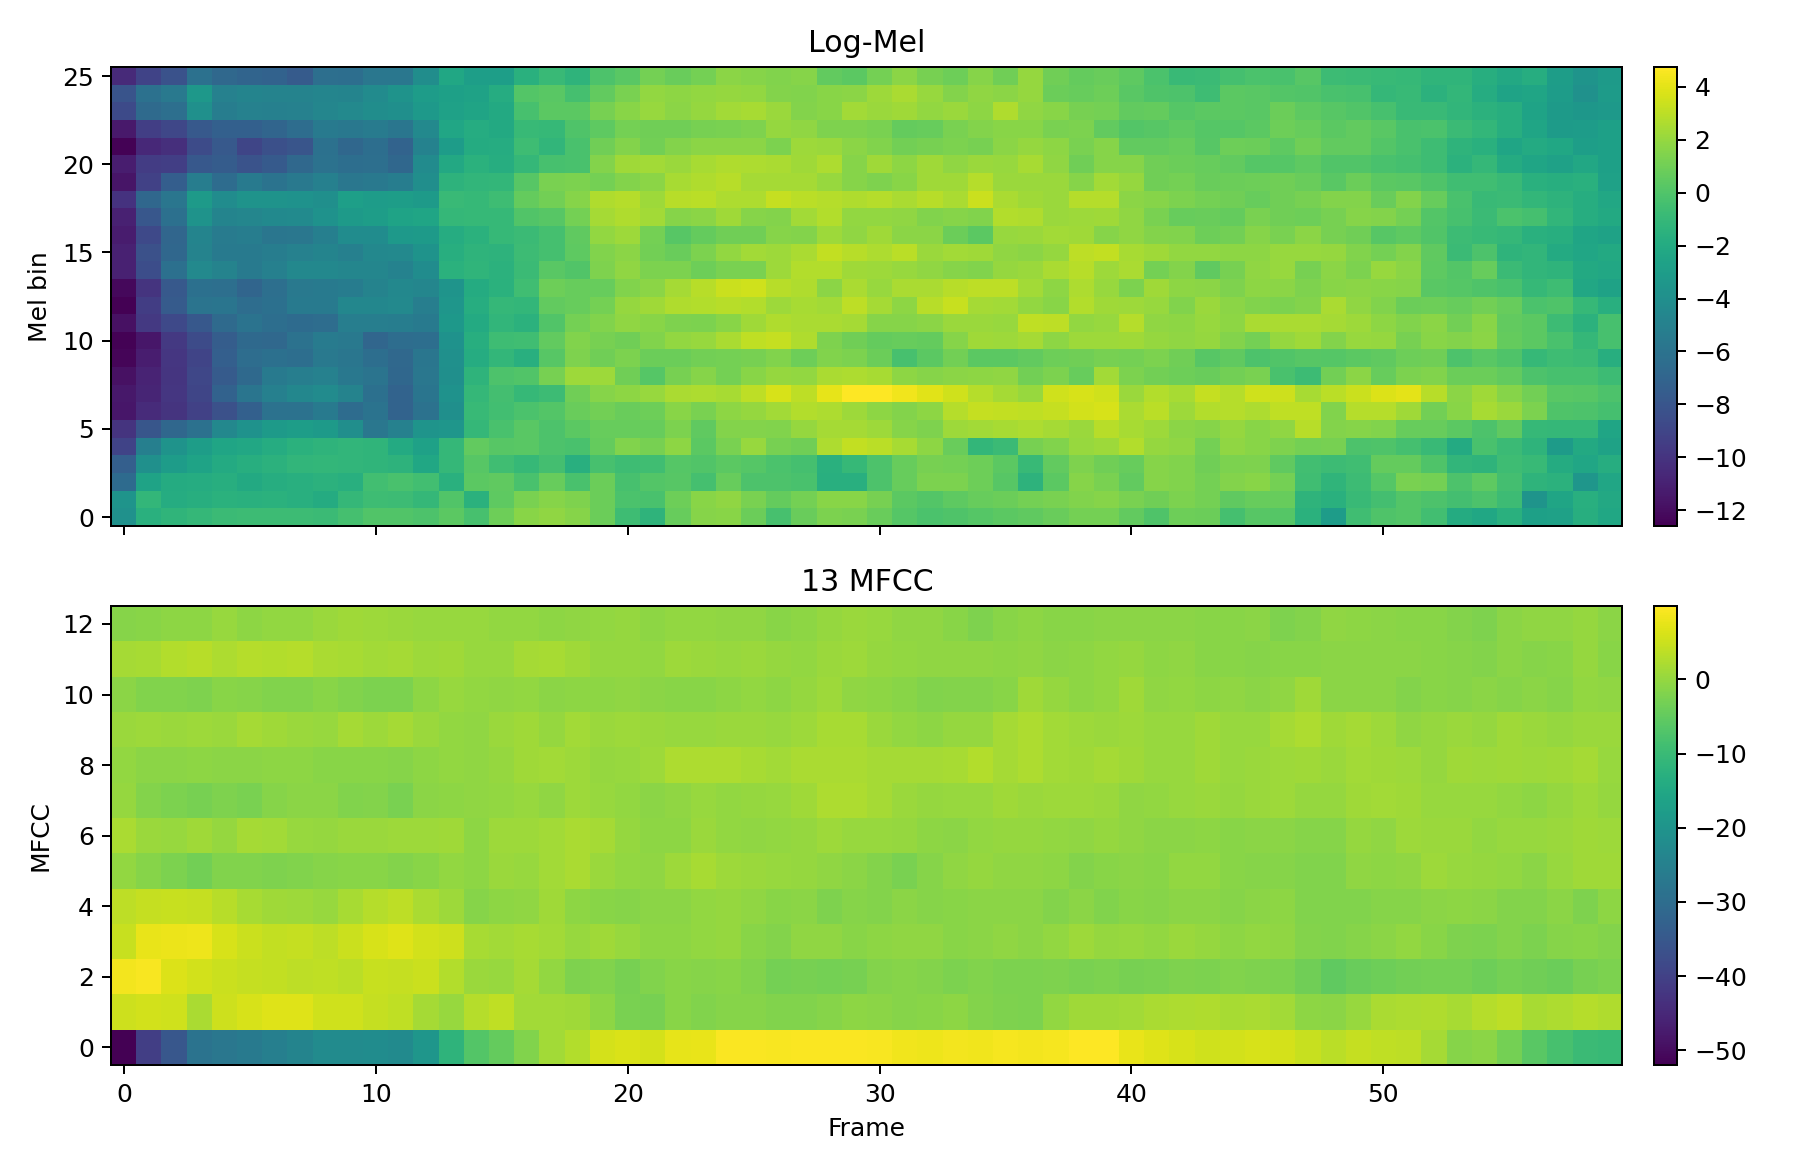

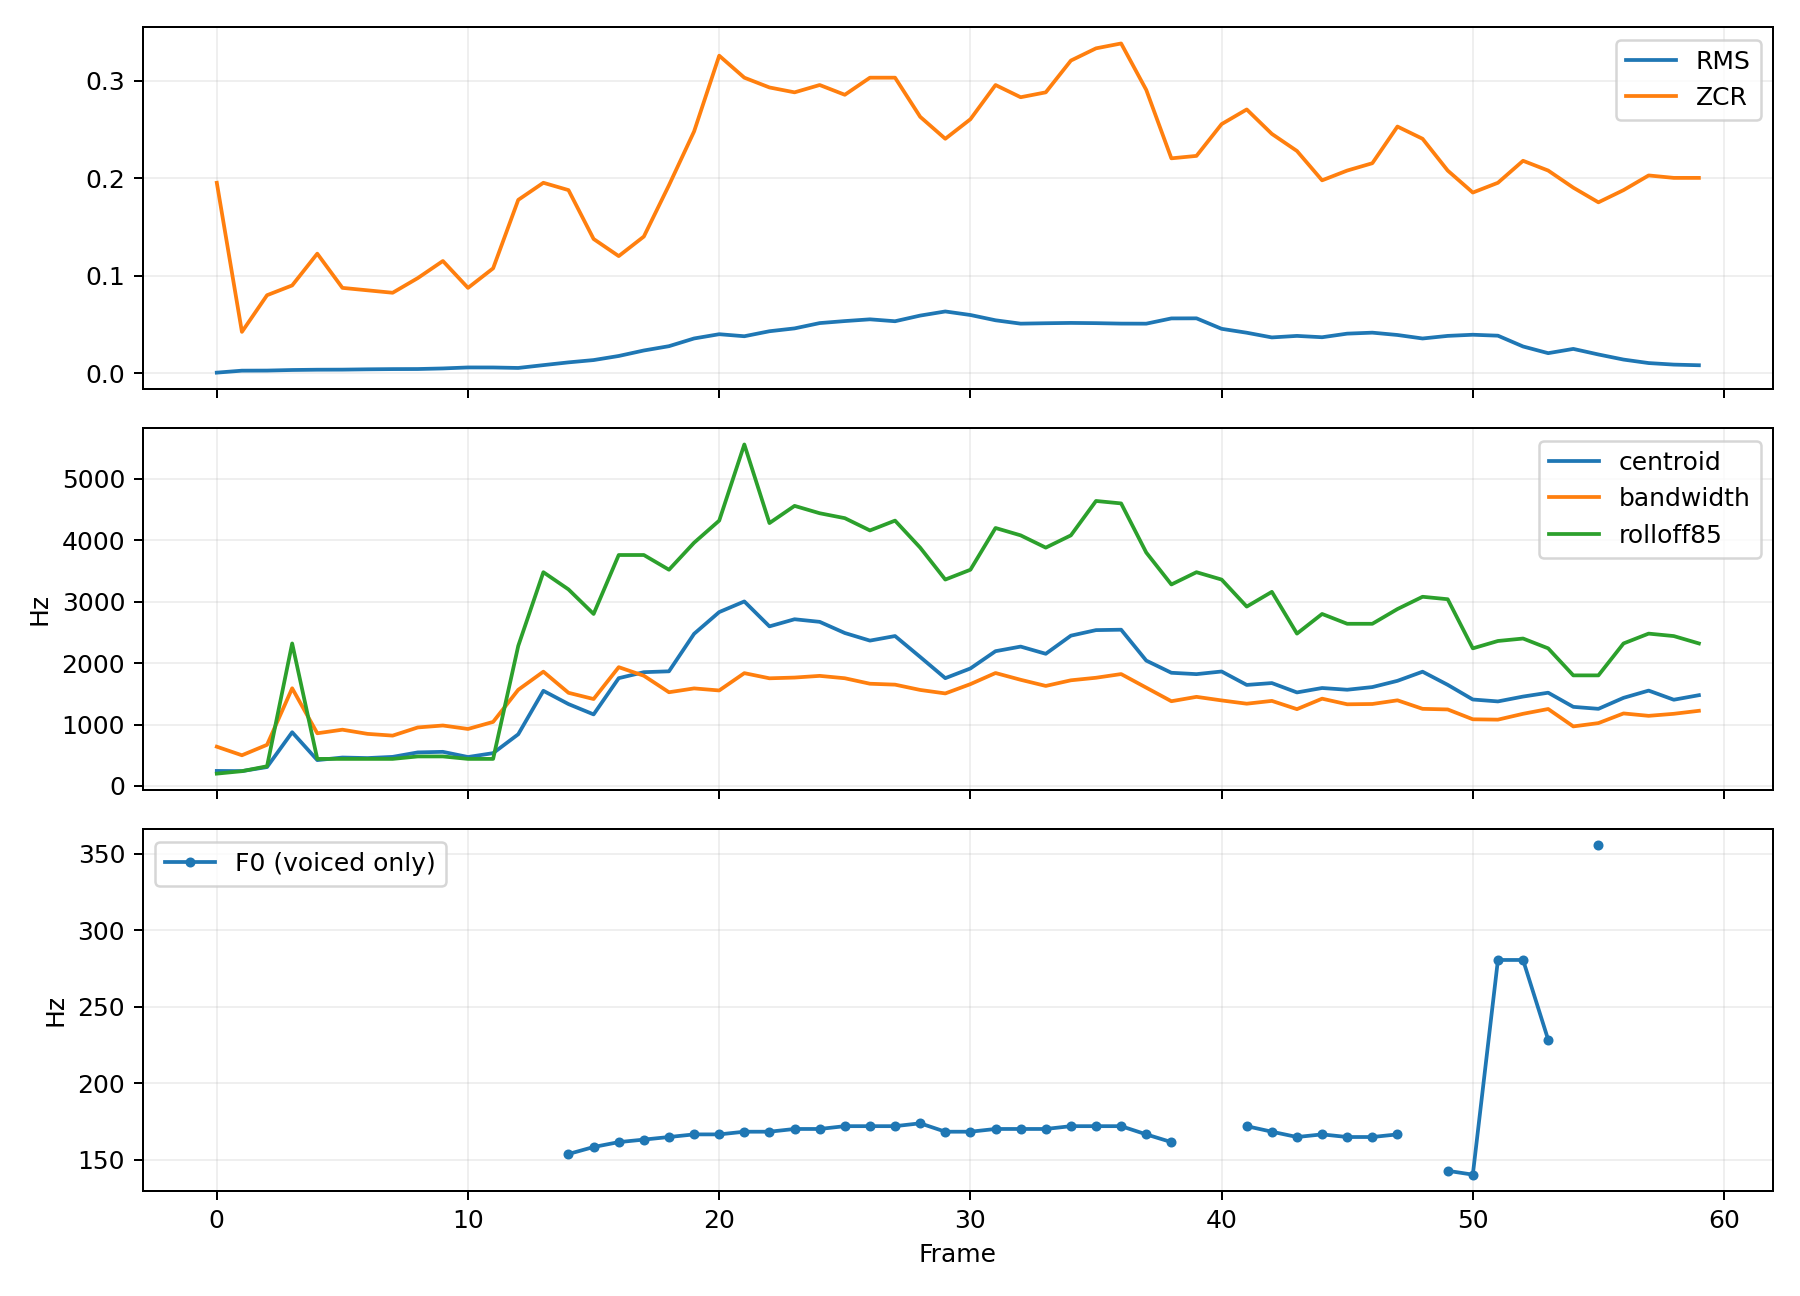

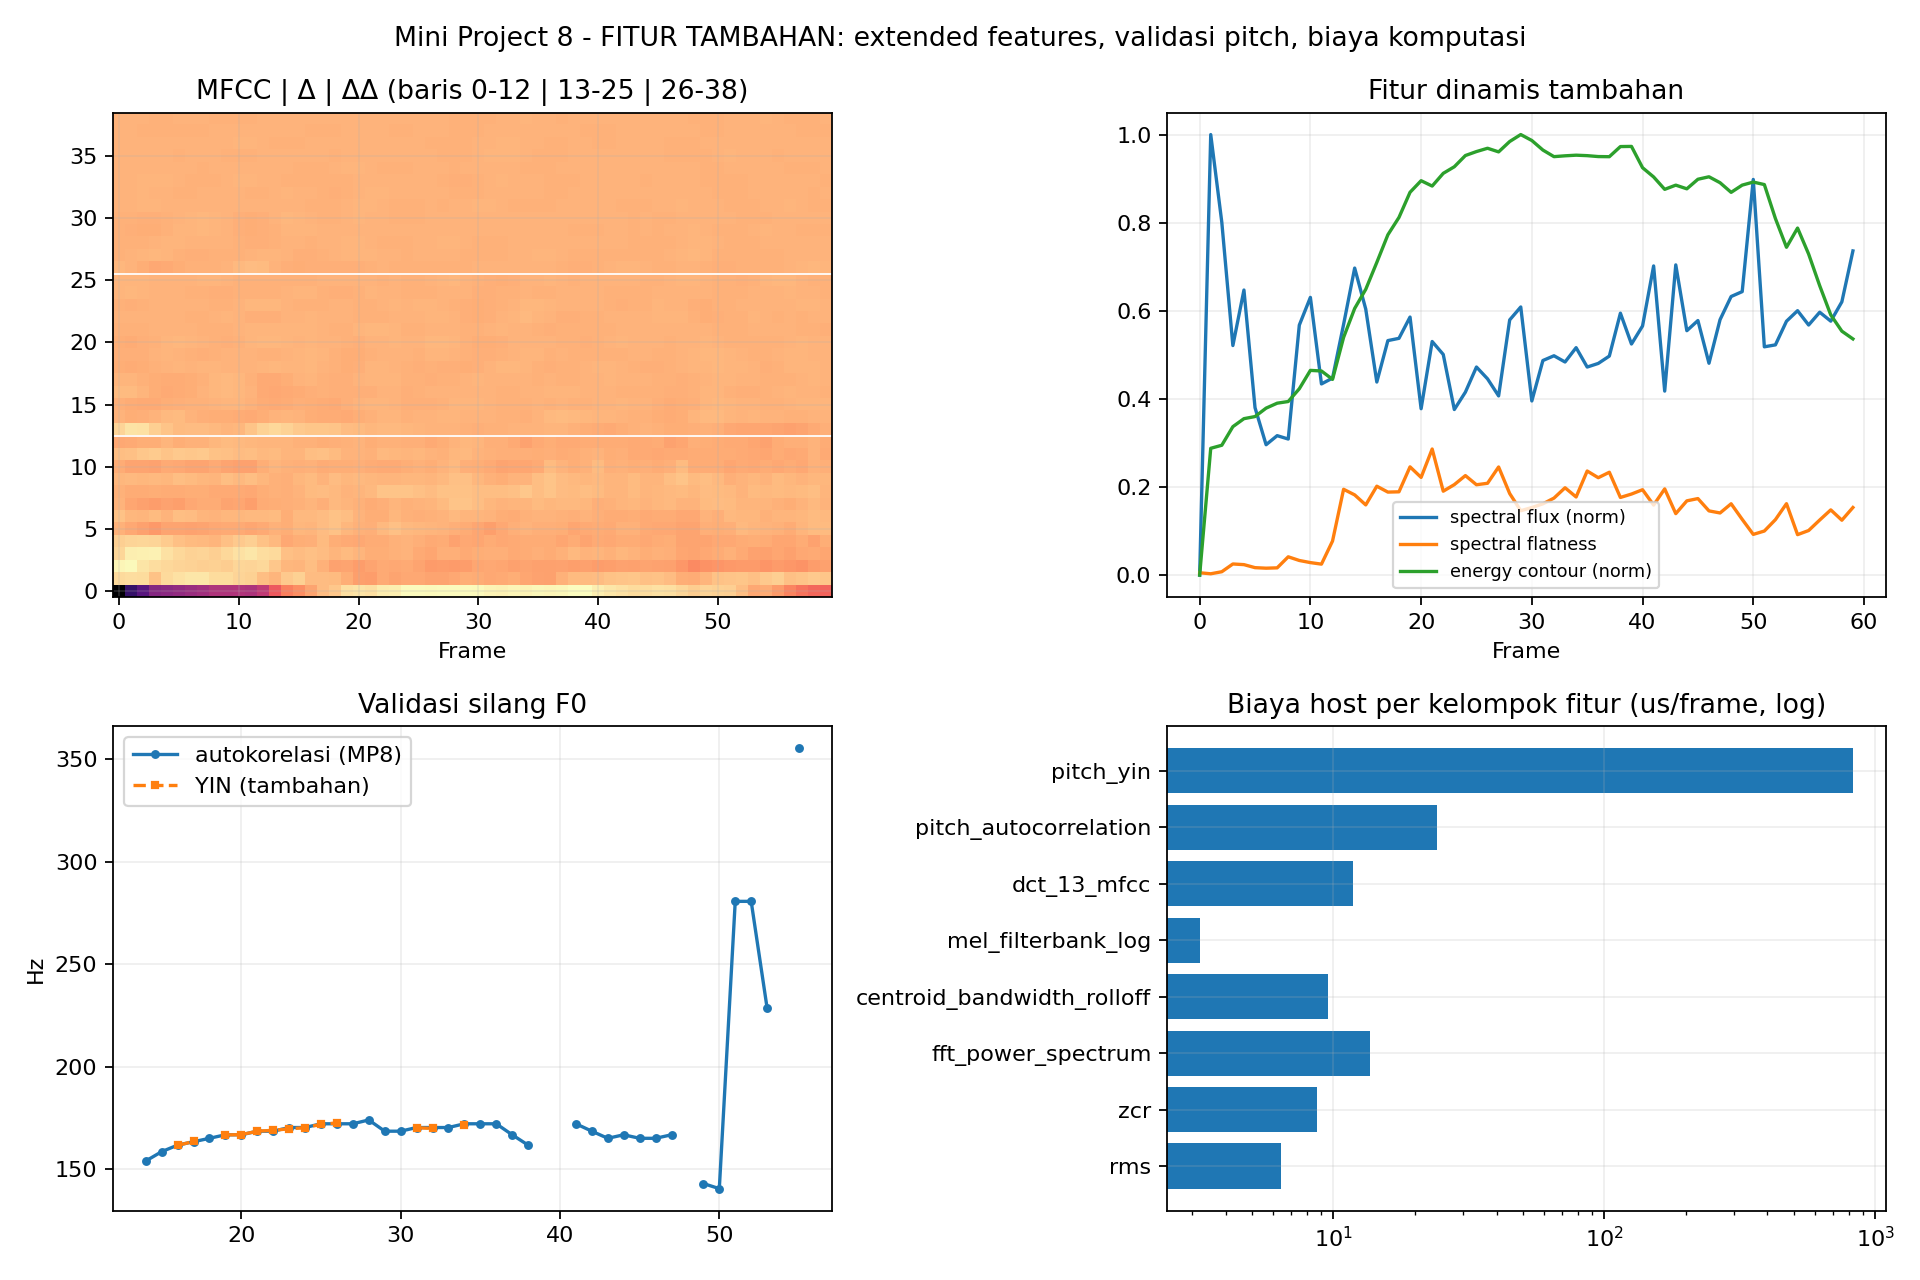

In [17]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp08_logmel_mfcc.png', 'mp08_scalar_features.png', 'mp08_extension_feature_analysis.png']:
        display(Image(filename=str(OUT_FIG/p), width=760))